# 01 — Train all three tiers

Trains Tier 1 (LightGBM), Tier 2 (frozen-encoder cross-attention fusion) and
Tier 3 (Tier 1 + pocket-occupancy features) across all four splits, and reports
PR-AUC, MCC and Brier score with error bars over 5 seeds.

## Why error bars, and why over *split* seeds

A single split of ~250 test rows carries a standard error on PR-AUC of several
points. Two methods differing by 0.02 on one seed are indistinguishable. We
therefore vary the **split seed and the model seed together**, because at this
sample size split variance dominates — reporting only model-seed variance
understates the uncertainty badly and makes tiers look more separable than a
rerun would show.

## Why a ceiling column

The synthetic cohort exposes `oracle_p`, the true generative probability. Its
PR-AUC is the **Bayes ceiling**: the best any model could achieve against this
much label noise. Without it, a PR-AUC of 0.45 is uninterpretable — it could be
a weak model or a noisy problem. `fraction_of_ceiling` is the honest summary.


> ## ⚠ These results are computed on SYNTHETIC data
>
> The curated benchmark this package is designed to consume
> ([`amenabench`](https://github.com/xX-its-amit-Xx/amenabench)) currently
> contains only a `LICENSE` file — there is no data in it. Every number and
> figure below is therefore produced by
> `foldrescue.data.SyntheticCohortAdapter`, a seeded generator whose labels
> encode a mixture **we chose**.
>
> **What this notebook demonstrates:** that the pipeline runs end to end, and
> that the diagnostics behave as designed against a known ground truth.
>
> **What it does not demonstrate:** anything about pharmacological chaperone
> biology. These are not findings. Do not cite these numbers.


In [1]:
import sys, warnings, time
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")          # cookbook/ -> repo root
sys.path.insert(0, ".")
from _viz import (SERIES, TIER_COLOR, BLOCK_COLOR, INK, INK_SECONDARY,
                  INK_MUTED, use_style, save, label_bars)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
# embed figures in the committed notebook, not just on disk
%matplotlib inline
use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.5.3 | pandas 3.0.5


In [2]:
from foldrescue.data import load_cohort
from foldrescue.features import FeatureSpec, build_features
from foldrescue.models import build_model
from foldrescue.evaluate import evaluate_predictions, aggregate_over_seeds
from foldrescue.embeddings import build_embedding_matrix

SEEDS   = [0, 1, 2, 3, 4]
SPLITS  = ["random", "gene_holdout", "compound_holdout", "scaffold"]
ECFP    = 256
CACHE   = "../.foldrescue_cache/embeddings"
PROT_DIM, COMP_DIM = 320, 768   # ESM-2 t6 8M, ChemBERTa-zinc-base-v1

# Tier 3 is the only tier given the structural block -- that is what defines it.
BLOCKS = {
    "tier1_gbm":       ("stability", "ligand", "interaction"),
    "tier3_structure": ("stability", "structural", "ligand", "interaction"),
}
print("tiers:", list(BLOCKS) + ["tier2_fusion"])
print("splits:", SPLITS)
print("seeds:", SEEDS)

tiers: ['tier1_gbm', 'tier3_structure', 'tier2_fusion']
splits: ['random', 'gene_holdout', 'compound_holdout', 'scaffold']
seeds: [0, 1, 2, 3, 4]


### Tier 2 runs on real ESM-2 and ChemBERTa — and still cannot win here

The protein side embeds a **real variant window**: the packaged UniProt
sequence for the gene, with the mutant residue substituted at the real
position. `wt_aa` is the genuine residue there, asserted in the test suite.
The compound side is real ChemBERTa over the real SMILES. No surrogates.

**But Tier 2 is structurally capped on this cohort, and the cap has nothing to
do with the encoders.** The synthetic labels are generated by crossing
compound descriptors against *variant tabular properties* — `ddg_pred`, `rsa`,
`dist_to_pocket`, `conservation` — and those are drawn from random
distributions, not computed from sequence. Measured on the cohort below, their
correlation with sequence position is ~0.02. So the variant-side generative
signal is **not a function of the sequence**, and no protein language model can
recover it, however good it is.

Tier 2's numbers here are therefore *not evidence about representation
fusion*. They say that an architecture which can only see sequence and
chemistry cannot recover a label built from hidden tabular variables — which is
true, and uninformative about the method. On a curated benchmark where
`ddg_pred` and `rsa` are real computed properties of the real structure, the
comparison becomes meaningful. Here it is not, and the ablation in notebook 04
is the better guide to what carries signal.

This is the clearest single limitation of using a synthetic cohort, and it
would be easy to miss: every number below is produced correctly, by real
encoders, and still cannot be read as a verdict on Tier 2.

In [3]:
_c0 = load_cohort("synthetic", seed=0)
_X, emb_prov = build_embedding_matrix(
    _c0, protein_backend="esm2", compound_backend="chemberta", cache_root=CACHE)
for k, v in emb_prov.items():
    print(f"{k:22s} {v}")
assert not emb_prov["surrogate"], "expected real pretrained encoders"
print("\nTier 2 embedding width:", _X.shape[1],
      f"(ESM-2 {PROT_DIM} + ChemBERTa {COMP_DIM})")

# The claim in the markdown above, measured rather than asserted.
import numpy as _np
_v = _c0.variants
print("\nCorrelation of sequence position with the variant-side generative terms:")
for _col in ("ddg_pred", "rsa", "conservation"):
    print(f"   position vs {_col:14s} r = {float(_np.corrcoef(_v.position, _v[_col])[0,1]):+.4f}")
print("-> the variant-side signal is not a function of sequence, so no protein")
print("   language model can recover it. Tier 2 is capped by the cohort, not the encoder.")

2026-10-10 22:12:10,753 INFO    foldrescue.data: synthetic cohort: 176 variants x 12 compounds -> 1389 pairs, prevalence 0.308


2026-10-10 22:12:10,755 INFO    foldrescue.embeddings: using 8 packaged UniProt sequences for variant windows


2026-10-10 22:12:10,770 INFO    foldrescue.embeddings: resumed embedding cache ../.foldrescue_cache/embeddings/protein_8bcdb868ed6d071e with 176 entities


2026-10-10 22:12:10,772 INFO    foldrescue.embeddings: all 176 entities already cached (../.foldrescue_cache/embeddings/protein_8bcdb868ed6d071e)


2026-10-10 22:12:10,774 INFO    foldrescue.embeddings: resumed embedding cache ../.foldrescue_cache/embeddings/compound_11ad55452536b962 with 12 entities


2026-10-10 22:12:10,774 INFO    foldrescue.embeddings: all 12 entities already cached (../.foldrescue_cache/embeddings/compound_11ad55452536b962)


protein_backend        esm2
protein_model          facebook/esm2_t6_8M_UR50D
compound_backend       chemberta
compound_model         seyonec/ChemBERTa-zinc-base-v1
surrogate              False
unfreeze_encoders      False

Tier 2 embedding width: 1088 (ESM-2 320 + ChemBERTa 768)

Correlation of sequence position with the variant-side generative terms:
   position vs ddg_pred       r = -0.0174
   position vs rsa            r = +0.0222
   position vs conservation   r = -0.0367
-> the variant-side signal is not a function of sequence, so no protein
   language model can recover it. Tier 2 is capped by the cohort, not the encoder.


In [4]:
rows = []
t_start = time.time()

for seed in SEEDS:
    cohort = load_cohort("synthetic", seed=seed)
    y_all = cohort.pairs["label"].to_numpy()

    # Tree tiers
    feats = {t: build_features(cohort, spec=FeatureSpec(blocks=b, ecfp_bits=ECFP))
             for t, b in BLOCKS.items()}
    # Fusion tier embeddings (cached + resumable across seeds)
    Xe, _ = build_embedding_matrix(cohort, protein_backend="esm2",
                                   compound_backend="chemberta", cache_root=CACHE)

    for split in SPLITS:
        s = cohort.split(split)
        for tier in list(BLOCKS) + ["tier2_fusion"]:
            if tier == "tier2_fusion":
                X = Xe
                model = build_model(tier, protein_dim=PROT_DIM, compound_dim=COMP_DIM,
                                    epochs=80, random_state=seed)
                model.fit(X[s["train"]], y_all[s["train"]],
                          eval_set=(X[s["calib"]], y_all[s["calib"]]))
                names = None
            else:
                fm = feats[tier]
                X, names = fm.X, fm.feature_names
                model = build_model(tier, random_state=seed)
                model.fit(X[s["train"]], y_all[s["train"]],
                          eval_set=(X[s["calib"]], y_all[s["calib"]]),
                          feature_names=names)

            m = evaluate_predictions(
                y_all[s["test"]], model.predict_proba(X[s["test"]]),
                split=split, tier=tier,
                y_calib=y_all[s["calib"]],
                p_calib=model.predict_proba(X[s["calib"]]),
                oracle_p_test=cohort.oracle_p[s["test"]],
            )
            row = m.as_row(); row["seed"] = seed
            rows.append(row)

raw = pd.DataFrame(rows)
print(f"{len(raw)} fits in {time.time()-t_start:.1f}s")
raw.head()

2026-10-10 22:12:11,141 INFO    foldrescue.data: synthetic cohort: 176 variants x 12 compounds -> 1389 pairs, prevalence 0.308


2026-10-10 22:12:11,166 INFO    foldrescue.features: built features: (1389, 289) (float64)


2026-10-10 22:12:11,185 INFO    foldrescue.features: built features: (1389, 300) (float64)


2026-10-10 22:12:11,187 INFO    foldrescue.embeddings: using 8 packaged UniProt sequences for variant windows


2026-10-10 22:12:11,195 INFO    foldrescue.embeddings: resumed embedding cache ../.foldrescue_cache/embeddings/protein_8bcdb868ed6d071e with 176 entities


...

2026-10-10 22:13:20,081 INFO    foldrescue.models: tier2: early stop at epoch 24 (best val 0.8439)


2026-10-10 22:13:22,347 INFO    foldrescue.models: tier2: early stop at epoch 21 (best val 0.9333)


2026-10-10 22:13:26,368 INFO    foldrescue.models: tier2: early stop at epoch 28 (best val 0.9643)


60 fits in 75.9s


,split,tier,n_test,prevalence,pr_auc,roc_auc,mcc,brier,ece,threshold,n_predicted_positive,oracle_pr_auc,fraction_of_ceiling,seed
0,random,tier1_gbm,278,0.327338,0.449568,0.627196,0.216308,0.210628,0.058833,0.400706,67,0.654296,0.373838,0
1,random,tier3_structure,278,0.327338,0.466748,0.624023,0.120918,0.211258,0.048872,0.271594,185,0.654296,0.426384,0
2,random,tier2_fusion,278,0.327338,0.347779,0.548452,-0.084287,0.259859,0.190605,0.720593,9,0.654296,0.062517,0
3,gene_holdout,tier1_gbm,374,0.299465,0.379563,0.625818,0.193810,0.208540,0.087594,0.316015,185,0.673006,0.214428,0
4,gene_holdout,tier3_structure,374,0.299465,0.462056,0.665673,0.185362,0.199370,0.076426,0.351329,100,0.673006,0.435270,0


### Results

`pr_auc` is always read next to `prevalence`: PR-AUC is only interpretable
relative to the base rate, since the no-skill baseline for average precision
*is* the prevalence.

In [5]:
agg = aggregate_over_seeds(raw.to_dict("records"), by=("split", "tier"))
view = agg[["split", "tier", "prevalence_mean", "pr_auc_mean", "pr_auc_std",
            "mcc_mean", "mcc_std", "brier_mean", "brier_std",
            "oracle_pr_auc_mean", "fraction_of_ceiling_mean"]].copy()
view.columns = ["split", "tier", "prev", "PR-AUC", "+/-", "MCC", "+/-",
                "Brier", "+/- ", "ceiling", "frac_ceiling"]
view = view.round(4)
print(view.to_string(index=False))
view.to_csv("../results/DEMO_synthetic_tier_comparison.csv", index=False)

           split            tier   prev  PR-AUC    +/-     MCC    +/-  Brier   +/-   ceiling  frac_ceiling
compound_holdout       tier1_gbm 0.3207  0.4281 0.0812  0.1513 0.0944 0.2144 0.0176   0.6141        0.3543
compound_holdout    tier2_fusion 0.3207  0.3713 0.0586  0.0363 0.0611 0.2729 0.0304   0.6141        0.1589
compound_holdout tier3_structure 0.3207  0.4179 0.0828  0.1356 0.0785 0.2129 0.0157   0.6141        0.3311
    gene_holdout       tier1_gbm 0.3005  0.4323 0.0693  0.1729 0.0939 0.2013 0.0119   0.6048        0.4391
    gene_holdout    tier2_fusion 0.3005  0.3446 0.0225  0.0525 0.0172 0.2551 0.0147   0.6048        0.1530
    gene_holdout tier3_structure 0.3005  0.4283 0.0944  0.0957 0.0963 0.2014 0.0063   0.6048        0.4108
          random       tier1_gbm 0.2956  0.4348 0.0327  0.1717 0.0676 0.2018 0.0087   0.5788        0.5128
          random    tier2_fusion 0.2956  0.3173 0.0286  0.0106 0.0839 0.2541 0.0150   0.5788        0.0836
          random tier3_structure 0.29

### PR-AUC by split and tier

Grey marks the no-skill baseline (the prevalence) and the dashed rule marks the
Bayes ceiling. The distance between those two is all the signal that exists;
anything a bar does outside that band is noise.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


wrote results/figures/01_pr_auc_by_split_tier.png


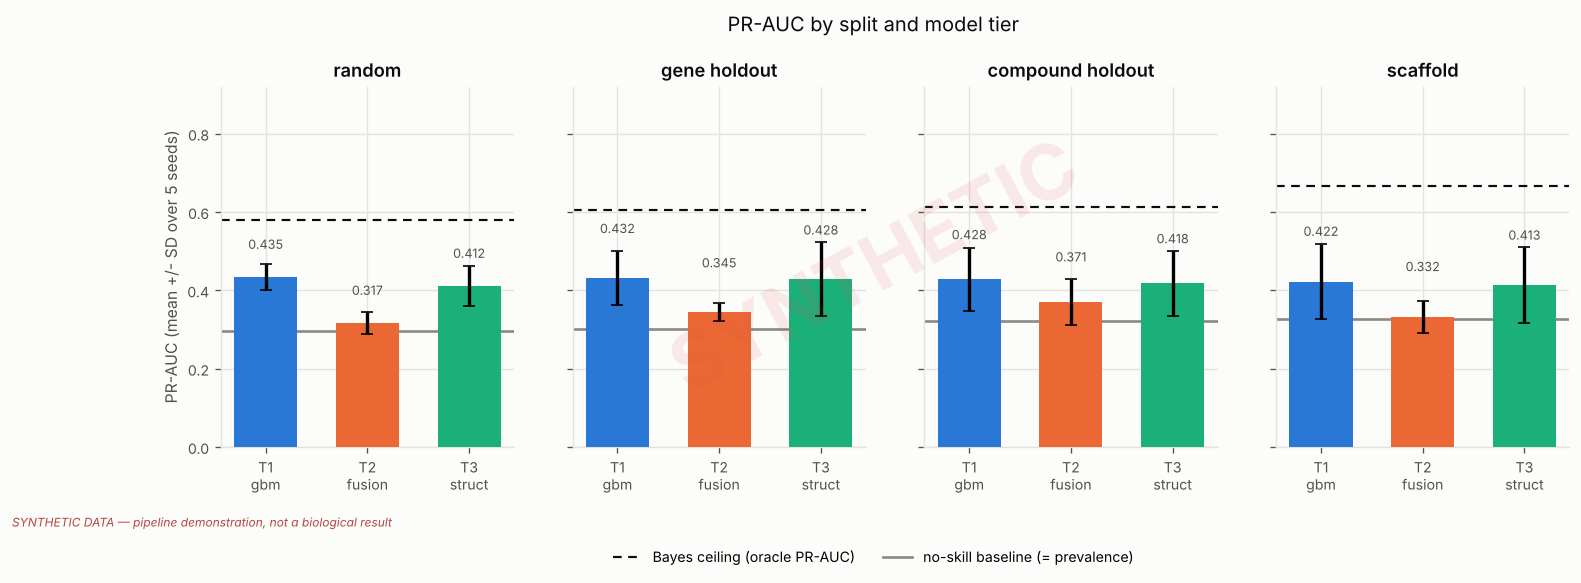

In [6]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(14.5, 3.9), sharey=True)
tiers = ["tier1_gbm", "tier2_fusion", "tier3_structure"]

for ax, split in zip(axes, SPLITS, strict=True):
    sub = agg[agg["split"] == split].set_index("tier")
    xs = np.arange(len(tiers))
    means = [sub.loc[t, "pr_auc_mean"] for t in tiers]
    errs  = [sub.loc[t, "pr_auc_std"] for t in tiers]
    bars = ax.bar(xs, means, yerr=errs, capsize=3.5, width=0.62,
                  color=[TIER_COLOR[t] for t in tiers], zorder=3)
    for b in bars:
        b.set_linewidth(0)
    prev = sub["prevalence_mean"].iloc[0]
    ceil = sub["oracle_pr_auc_mean"].iloc[0]
    ax.axhline(prev, color=INK_MUTED, lw=1.6, zorder=2)
    ax.axhline(ceil, color=INK, lw=1.3, ls=(0, (4, 3)), zorder=2)
    label_bars(ax, bars, means, dy=max(errs) + 0.012)
    ax.set_title(split.replace("_", " "))
    ax.set_xticks(xs)
    ax.set_xticklabels(["T1\ngbm", "T2\nfusion", "T3\nstruct"])
    ax.set_ylim(0, 0.92)

axes[0].set_ylabel("PR-AUC (mean +/- SD over 5 seeds)")

# The two reference lines need naming in the figure itself: an annotation
# placed past the last bar gets clipped by the axes, which left both rules
# unexplained in an earlier render.
from matplotlib.lines import Line2D
fig.legend(
    handles=[
        Line2D([], [], color=INK, lw=1.3, ls=(0, (4, 3)),
               label="Bayes ceiling (oracle PR-AUC)"),
        Line2D([], [], color=INK_MUTED, lw=1.6,
               label="no-skill baseline (= prevalence)"),
    ],
    loc="lower center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False,
)
fig.suptitle("PR-AUC by split and model tier", y=1.04, fontsize=12, color=INK)
save(fig, "01_pr_auc_by_split_tier.png")
plt.show()

### Does the fancy tier win?

In [7]:
piv = agg.pivot(index="split", columns="tier", values="pr_auc_mean").round(4)
sd  = agg.pivot(index="split", columns="tier", values="pr_auc_std").round(4)
print("PR-AUC means:\n", piv.to_string(), "\n")
print("PR-AUC SDs:\n", sd.to_string(), "\n")

for split in SPLITS:
    best = piv.loc[split].idxmax()
    t1, t3 = piv.loc[split, "tier1_gbm"], piv.loc[split, "tier3_structure"]
    pooled = float(np.hypot(sd.loc[split, "tier1_gbm"], sd.loc[split, "tier3_structure"]))
    sep = "separable" if abs(t3 - t1) > pooled else "NOT separable given seed variance"
    print(f"{split:18s} best={best:16s} tier3-tier1={t3-t1:+.4f}  ({sep})")

PR-AUC means:
 tier              tier1_gbm  tier2_fusion  tier3_structure
split                                                     
compound_holdout     0.4281        0.3713           0.4179
gene_holdout         0.4323        0.3446           0.4283
random               0.4348        0.3173           0.4118
scaffold             0.4224        0.3324           0.4127 

PR-AUC SDs:
 tier              tier1_gbm  tier2_fusion  tier3_structure
split                                                     
compound_holdout     0.0812        0.0586           0.0828
gene_holdout         0.0693        0.0225           0.0944
random               0.0327        0.0286           0.0515
scaffold             0.0953        0.0402           0.0970 

random             best=tier1_gbm        tier3-tier1=-0.0230  (NOT separable given seed variance)
gene_holdout       best=tier1_gbm        tier3-tier1=-0.0040  (NOT separable given seed variance)
compound_holdout   best=tier1_gbm        tier3-tier1=-0.0102  (N

### What to take from this

Read the printed comparison above rather than a remembered headline. Three
things are worth stating regardless of the exact numbers:

1. **The interpretable baseline is hard to beat at this sample size.** With
   ~10³ pairs, gradient-boosted trees over hand-built features are a strong
   model, and a cross-attention fusion head on frozen (here, surrogate)
   embeddings has far more capacity than the data supports. This is the
   expected result, not a disappointing one — it is why Tier 1 exists.
2. **Differences smaller than the pooled seed SD are not differences.** The
   separability check above says so explicitly for each split.
3. **The split choice matters more than the tier choice.** `random` is the most
   optimistic number in the table and answers the least useful question;
   `gene_holdout` answers "a protein I have never trained on", which is what a
   prospective query actually is.
